# Módulo 04: Transporte de Fangos y Mezclas Arena–Fango (`sedmor.tidal_transport`)

Las mezclas de sedimentos cohesivos (arcillas/limos) y no cohesivos (arenas) presentan acoplamientos no lineales clave: **floculación dependiente de la concentración**, **amortiguamiento de la turbulencia por estratificación**, **transporte neto residual por gradiente de salinidad** y **aumento de la cohesión crítica del lecho**.

### Objetivos de aprendizaje
1. Simular un ciclo mareal completo dominado por fango mediante `tidal_mud_sand_transport`, observando el rezago (*settling lag* / *scour lag*) y los perfiles verticales de concentración.
2. Analizar mezclas dominadas por arena (`tidal_sand_mud_transport`) frente a distintos contenidos de fango $p_{\text{mud}}$ y alturas de ola.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sedmor as sm

plt.rcParams["figure.dpi"] = 110
print(f"Librería sedmor v{sm.__version__} cargada.")


Librería sedmor v0.1.0 cargada.


## 1. Simulación Mareal de Fango y Arena (`tidal_mud_sand_transport`)

Simulamos una columna de agua de $h = 10\,\text{m}$ con onda de marea de amplitud $1.0\,\text{m}$, velocidad pico $0.90\,\text{m/s}$ y una mezcla de fondo con $70\%$ de fango y $30\%$ de arena muy fina, incluyendo el efecto de gradiente longitudinal de salinidad.


Transporte residual neto fango: 73546.08 kg/m | arena: 11701.71 kg/m
Transporte residual por flujo gravitacional de densidad: 1569.33 kg/m


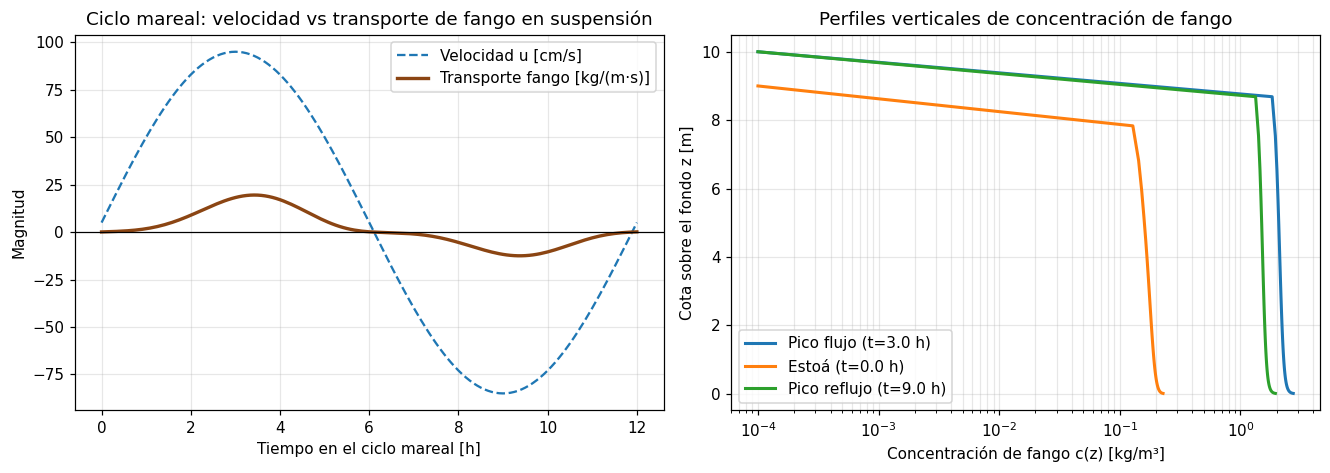

In [2]:
sim_mud = sm.tidal_transport.tidal_mud_sand_transport(
    depth=10.0, wave_height=0.5, wave_period=6.0,
    u_net=0.05, u_peak=0.90, tidal_amplitude=1.0,
    p_mud=0.70, p_sand=0.30, ws_mud_mode=2, damping_coef=1.0
)

print(f"Transporte residual neto fango: {sim_mud.mud_net:.2f} kg/m | arena: {sim_mud.sand_net:.2f} kg/m")
print(f"Transporte residual por flujo gravitacional de densidad: {sim_mud.density_net:.2f} kg/m")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.4))

t_h = sim_mud.time / 3600.0
ax1.plot(t_h, sim_mud.velocity * 100.0, "--", color="tab:blue", label="Velocidad u [cm/s]")
ax1.plot(t_h, sim_mud.suspended_mud_rate, color="saddlebrown", lw=2.2, label="Transporte fango [kg/(m·s)]")
ax1.axhline(0.0, color="k", lw=0.8)
ax1.set_xlabel("Tiempo en el ciclo mareal [h]")
ax1.set_ylabel("Magnitud")
ax1.set_title("Ciclo mareal: velocidad vs transporte de fango en suspensión")
ax1.grid(alpha=0.3)
ax1.legend()

# Seleccionamos 3 instantes representativos del perfil vertical de concentración
idx_peak_flood = int(np.argmax(sim_mud.velocity))
idx_slack = int(np.argmin(np.abs(sim_mud.velocity[:len(t_h)//2])))
idx_peak_ebb = int(np.argmin(sim_mud.velocity))

for idx, lbl in [(idx_peak_flood, "Pico flujo"), (idx_slack, "Estoá"), (idx_peak_ebb, "Pico reflujo")]:
    ax2.semilogx(
        np.maximum(sim_mud.c_mud_profiles_mass[:, idx], 1e-4),
        sim_mud.z_profiles[:, idx],
        lw=2,
        label=f"{lbl} (t={t_h[idx]:.1f} h)",
    )
ax2.set_xlabel("Concentración de fango c(z) [kg/m³]")
ax2.set_ylabel("Cota sobre el fondo z [m]")
ax2.set_title("Perfiles verticales de concentración de fango")
ax2.grid(alpha=0.3, which="both")
ax2.legend()

plt.tight_layout()
plt.show()


## 2. Mezcla Dominada por Arena: Efecto de la Fracción de Fango ($p_{\text{mud}}$)

Cuando una arena contiene entre $5\%$ y $35\%$ de finos cohesivos, el umbral crítico de erosión aumenta sustancialmente reduciendo la tasa neta de transporte. Evaluamos esta sensibilidad con `tidal_sand_mud_transport`.


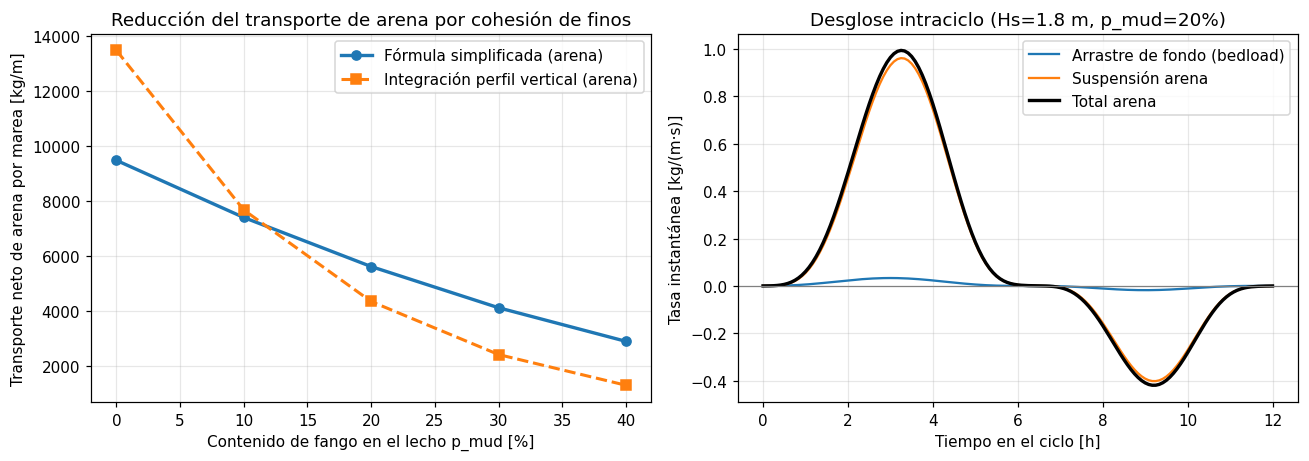

In [3]:
p_muds = np.array([0.0, 0.10, 0.20, 0.30, 0.40])
sand_net_formula = []
sand_net_profile = []

for pm in p_muds:
    r_sm = sm.tidal_transport.tidal_sand_mud_transport(
        depth=15.0, wave_height=1.8, wave_period=7.0, u_net=0.12, u_peak=0.95,
        p_sand=1.0 - pm, p_mud=float(pm)
    )
    sand_net_formula.append(r_sm.sand_formula_net)
    sand_net_profile.append(r_sm.sand_profile_net)

r_ref = sm.tidal_transport.tidal_sand_mud_transport(
    depth=15.0, wave_height=1.8, wave_period=7.0, u_net=0.12, u_peak=0.95, p_sand=0.80, p_mud=0.20
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))

ax1.plot(p_muds * 100, sand_net_formula, "o-", lw=2.2, label="Fórmula simplificada (arena)")
ax1.plot(p_muds * 100, sand_net_profile, "s--", lw=2.0, label="Integración perfil vertical (arena)")
ax1.set_xlabel("Contenido de fango en el lecho p_mud [%]")
ax1.set_ylabel("Transporte neto de arena por marea [kg/m]")
ax1.set_title("Reducción del transporte de arena por cohesión de finos")
ax1.grid(alpha=0.3)
ax1.legend()

t_h2 = r_ref.time / 3600.0
ax2.plot(t_h2, r_ref.bedload_sand, label="Arrastre de fondo (bedload)")
ax2.plot(t_h2, r_ref.suspended_sand_formula_adj, label="Suspensión arena")
ax2.plot(t_h2, r_ref.total_sand_formula, lw=2.2, color="k", label="Total arena")
ax2.axhline(0.0, color="gray", lw=0.8)
ax2.set_xlabel("Tiempo en el ciclo [h]")
ax2.set_ylabel("Tasa instantánea [kg/(m·s)]")
ax2.set_title("Desglose intraciclo (Hs=1.8 m, p_mud=20%)")
ax2.grid(alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


### Ejercicios propuestos
1. Active o desactive el amortiguamiento turbulento (`damping_coef = 0.0` vs `1.0`) en `tidal_mud_sand_transport` y compare la concentración media cerca del fondo.
2. Observe cómo cambia el transporte neto de arena en `tidal_sand_mud_transport` si se anula el oleaje (`wave_height = 0.0`).
